# Experiment 03_3 — CamemBERT Deep Learning Fine-Tuning

Goal: Evaluate transfer learning on French product texts using pre-trained `camembert-base` and compare it with the TF-IDF + SVM baseline.

1. **Architecture & Setup**: Pre-trained CamemBERT transformer (110M parameters) fine-tuned on title and description text.
2. **Learning Dynamics**: Convergence inspection via 500-step training and validation loss tracking with linear warmup/decay schedule.
3. **Per-Category Performance**: Head-to-head comparison of per-class F1 gains against the optimised LinearSVC model.
4. **Error Analysis**: Systematic evaluation of top confused class pairs between traditional and deep learning approaches.


## 1. Training setup

| Setting | Value |
|---|---|
| Model | CamemBERT base (110 million parameters) |
| Input | Title and description, truncated to 128 tokens |
| Epochs | 2 |
| Batch size | 16 |
| Optimiser | AdamW |
| Learning rate | 0.00005, linear warmup (6% of steps) then linear decay |
| Weight decay (L2 regularisation) | 0.01 |
| Dropout | 0.1 |
| Gradient clipping | 1.0 |

These are standard values for fine-tuning BERT-type models. They were not tuned with cross-validation, because one training run takes about 2 hours.

- Weight decay and dropout are regularisation: they reduce overfitting.
- Gradient clipping limits very large updates and keeps training stable.

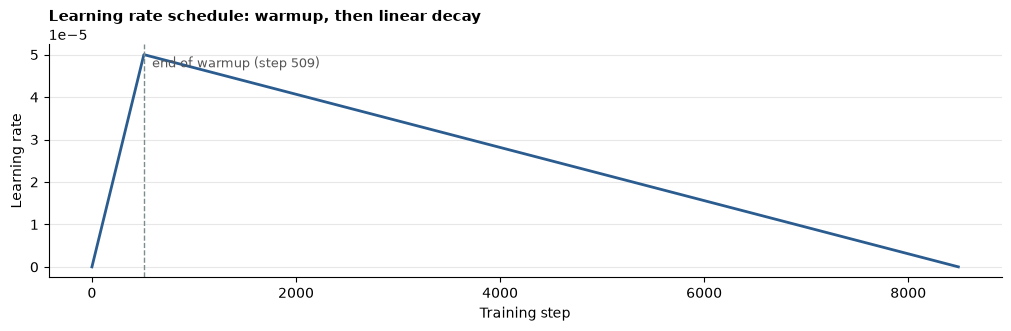

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Resolve repository root directory & Python path
PROJECT_ROOT             = Path.cwd().resolve()
while PROJECT_ROOT.name in {"03_text_fineTuning", "notebooks"}:
    PROJECT_ROOT         = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.categories import CATEGORY_NAMES
from src.metrics import compute_per_class_metrics

TOTAL_STEPS              = 8492
WARMUP_RATIO             = 0.06
MAX_LEARNING_RATE        = 5e-5

warmup_steps             = int(WARMUP_RATIO * TOTAL_STEPS)
steps                    = np.arange(TOTAL_STEPS)
learning_rate            = np.where(
    steps < warmup_steps,
    MAX_LEARNING_RATE * steps / warmup_steps,
    MAX_LEARNING_RATE * (TOTAL_STEPS - steps) / (TOTAL_STEPS - warmup_steps),
)

fig, ax                  = plt.subplots(figsize=(10, 3.2), constrained_layout=True)
ax.plot(steps, learning_rate, color="#2b5c8f", linewidth=2)
ax.axvline(warmup_steps, color="#7f8c8d", linestyle="--", linewidth=1)
ax.text(warmup_steps + 80, 0.000047, f"end of warmup (step {warmup_steps})", color="#555555", fontsize=9)
ax.set_title("Learning rate schedule: warmup, then linear decay", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Training step")
ax.set_ylabel("Learning rate")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()


### Analysis

- Warmup (first 509 steps): the learning rate increases from 0 to 0.00005. The classification layer starts with random weights, so large updates at the start could damage the pre-trained weights.
- Linear decay: the learning rate then decreases to 0, so the final updates are small.

## 2. Training

The code below fine-tunes CamemBERT on the 67932 training products. One run takes about 2 hours on an Apple M1 Pro GPU.

With `RUN_TRAINING = False`, the notebook skips training and uses the saved results from the last run. Set it to `True` to train again.

In [2]:
import time

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

RUN_TRAINING = False

MODEL_NAME = "almanach/camembert-base"
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 2
LEARNING_RATE = 5e-5
WARMUP_SHARE = 0.06
SEED = 42

# Train and validation loss are logged every LOG_EVERY steps,
# the validation loss on a fixed sample of LOSS_SAMPLE products.
LOG_EVERY = 500
LOSS_SAMPLE = 2000

TRAIN_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "text_train_processed.csv"
PROBABILITIES_PATH = PROJECT_ROOT / "data" / "processed" / "camembert_validation_probabilities.csv"
TRAINING_LOG_PATH = PROJECT_ROOT / "data" / "processed" / "camembert_training_log.csv"
EPOCH_SCORES_PATH = PROJECT_ROOT / "data" / "processed" / "camembert_epoch_scores.csv"
MODEL_DIR = PROJECT_ROOT / "models" / "camembert"


def batches(texts, labels, batch_size, shuffle, rng=None):
    order = rng.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for start in range(0, len(texts), batch_size):
        idx = order[start:start + batch_size]
        yield [texts[i] for i in idx], labels[idx]


def encode(tokenizer, texts, device):
    return tokenizer(texts, truncation=True, max_length=MAX_LENGTH,
                     padding=True, return_tensors="pt").to(device)


def cross_entropy(probabilities, labels):
    """Mean of -log(probability given to the true class)."""
    true_probability = probabilities[np.arange(len(labels)), labels]
    return float(-np.log(np.clip(true_probability, 1e-12, None)).mean())


def predict_probabilities(model, tokenizer, texts, device):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for batch_texts, _ in batches(texts, np.zeros(len(texts)), 64, shuffle=False):
            logits = model(**encode(tokenizer, batch_texts, device)).logits
            probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
    if device == "mps":
        torch.mps.empty_cache()  # otherwise memory grows and macOS starts swapping
    model.train()
    return np.concatenate(probabilities)

In [3]:
def train_camembert():
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"

    data = pd.read_csv(TRAIN_DATA_PATH)
    data["text_combined"] = data["text_combined"].fillna("")
    train = data[data["split"] == "train"]
    validation = data[data["split"] == "validation"]

    classes = np.sort(data["prdtypecode"].unique())
    class_index = {code: i for i, code in enumerate(classes)}
    train_texts = train["text_combined"].tolist()
    train_labels = train["prdtypecode"].map(class_index).to_numpy()
    validation_texts = validation["text_combined"].tolist()
    validation_labels = validation["prdtypecode"].map(class_index).to_numpy()

    sample = rng.choice(len(validation_texts), LOSS_SAMPLE, replace=False)
    sample_texts = [validation_texts[i] for i in sample]
    sample_labels = validation_labels[sample]

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(classes)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    total_steps = EPOCHS * int(np.ceil(len(train_texts) / BATCH_SIZE))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_SHARE * total_steps), total_steps)

    start = time.time()
    step = 0
    loss_log, epoch_scores = [], []
    running_loss, steps_since_log = 0.0, 0
    model.train()

    for epoch in range(1, EPOCHS + 1):
        for batch_texts, batch_labels in batches(train_texts, train_labels, BATCH_SIZE, shuffle=True, rng=rng):
            labels = torch.tensor(batch_labels, dtype=torch.long, device=device)
            loss = model(**encode(tokenizer, batch_texts, device), labels=labels).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

            step += 1
            running_loss += loss.item()
            steps_since_log += 1

            if step % LOG_EVERY == 0:
                sample_probabilities = predict_probabilities(model, tokenizer, sample_texts, device)
                row = {
                    "epoch": epoch,
                    "step": step,
                    "train_loss": running_loss / steps_since_log,
                    "validation_loss": cross_entropy(sample_probabilities, sample_labels),
                }
                loss_log.append(row)
                pd.DataFrame(loss_log).to_csv(TRAINING_LOG_PATH, index=False)
                print(f"epoch {epoch} | step {step}/{total_steps} | train loss {row['train_loss']:.3f} | "
                      f"validation loss {row['validation_loss']:.3f} | {(time.time() - start) / 60:.0f} min")
                running_loss, steps_since_log = 0.0, 0

        probabilities = predict_probabilities(model, tokenizer, validation_texts, device)
        predicted = classes[probabilities.argmax(axis=1)]
        scores = {
            "epoch": epoch,
            "validation_loss": cross_entropy(probabilities, validation_labels),
            "weighted_f1": f1_score(validation["prdtypecode"], predicted, average="weighted"),
            "macro_f1": f1_score(validation["prdtypecode"], predicted, average="macro"),
        }
        epoch_scores.append(scores)
        pd.DataFrame(epoch_scores).to_csv(EPOCH_SCORES_PATH, index=False)
        print(f"epoch {epoch} done | validation loss {scores['validation_loss']:.3f} | "
              f"weighted F1 {scores['weighted_f1']:.4f} | macro F1 {scores['macro_f1']:.4f}")

    output = pd.DataFrame(probabilities, columns=[str(c) for c in classes])
    output.insert(0, "row_id", validation["row_id"].to_numpy())
    output.to_csv(PROBABILITIES_PATH, index=False)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(MODEL_DIR)
    tokenizer.save_pretrained(MODEL_DIR)
    print(f"Saved validation probabilities and model. Total time: {(time.time() - start) / 60:.0f} min")


if RUN_TRAINING:
    train_camembert()
else:
    print("Training skipped: using the saved results of the last run.")

Training skipped: using the saved results of the last run.


## 3. Training curve

Every 500 steps, we measure:
- Train loss: the average cross-entropy loss over the last 500 training batches.
- Validation loss: the cross-entropy loss on a fixed sample of 2000 validation products.

If the validation loss stops decreasing while the train loss keeps decreasing, the model is overfitting.

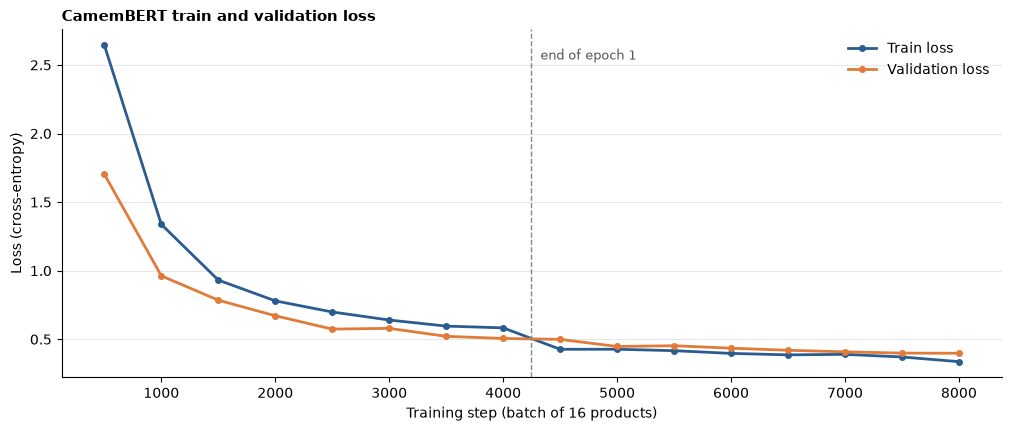

Epoch,Validation loss,Validation weighted F1,Validation macro F1
1,0.5010,0.8527,0.8314
2,0.4269,0.8765,0.8594


In [4]:
LOG_PATH                 = PROJECT_ROOT / "data" / "processed" / "camembert_training_log.csv"
SCORES_PATH              = PROJECT_ROOT / "data" / "processed" / "camembert_epoch_scores.csv"

log                      = pd.read_csv(LOG_PATH)
epoch_scores             = pd.read_csv(SCORES_PATH)

# The first log of epoch 2 (step 4500) was averaged over 500 steps but covers only the 254 steps
# since epoch 2 started. Rescale it to a true average.
STEPS_PER_EPOCH          = 4246
first_epoch2_mask        = (log["epoch"] == 2) & (log["step"] == log.loc[log["epoch"] == 2, "step"].min())
log.loc[first_epoch2_mask, "train_loss"] *= 500 / (log.loc[first_epoch2_mask, "step"] - STEPS_PER_EPOCH)

fig, ax                  = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
ax.plot(log["step"], log["train_loss"], color="#2b5c8f", linewidth=2, marker="o", markersize=4, label="Train loss")
ax.plot(log["step"], log["validation_loss"], color="#e07b39", linewidth=2, marker="o", markersize=4, label="Validation loss")
ax.axvline(STEPS_PER_EPOCH, color="#7f8c8d", linestyle="--", linewidth=1)
ax.text(STEPS_PER_EPOCH + 80, ax.get_ylim()[1] * 0.92, "end of epoch 1", color="#555555", fontsize=9)
ax.set_title("CamemBERT train and validation loss", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Training step (batch of 16 products)")
ax.set_ylabel("Loss (cross-entropy)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

display(
    epoch_scores.rename(columns={
        "epoch": "Epoch", "validation_loss": "Validation loss",
        "weighted_f1": "Validation weighted F1", "macro_f1": "Validation macro F1",
    }).style.hide(axis="index").format(precision=4)
)


### Analysis

- Both losses fall quickly in the first 1000 steps, then more slowly.
- Validation loss keeps going down until the end: 0.501 after epoch 1, 0.427 after epoch 2. So the model is not overfitting.
- In epoch 2, train loss drops a little below validation loss, because the model sees each training product for the second time. The gap is small (0.34 against 0.40 at the last measure). A third epoch could start to overfit, so 2 epochs is a reasonable stop.
- Validation weighted F1: 0.8527 after epoch 1, 0.8765 after epoch 2.
- The train loss point at step 4500 is rescaled: it was logged as an average over 500 steps but covered only the 254 steps since epoch 2 started.

## 4. CamemBERT vs TF-IDF + SVM

Both are scored on the same 16984 validation products. The SVM is the optimised model from notebook 04.

In [5]:
DATA_PATH                = PROJECT_ROOT / "data" / "processed" / "text_train_processed.csv"
CAMEMBERT_PROBS_PATH     = PROJECT_ROOT / "data" / "processed" / "camembert_validation_probabilities.csv"
SVM_PROBS_PATH           = PROJECT_ROOT / "data" / "processed" / "text_validation_probabilities.csv"

validation               = pd.read_csv(DATA_PATH)
validation               = validation[validation["split"] == "validation"][["row_id", "prdtypecode"]]

camembert                = pd.read_csv(CAMEMBERT_PROBS_PATH)
svm                      = pd.read_csv(SVM_PROBS_PATH)
classes                  = np.array([int(c) for c in camembert.columns[1:]])

camembert                = validation.merge(camembert, on="row_id")
svm                      = validation.merge(svm, on="row_id")
y_true                   = camembert["prdtypecode"].to_numpy()
pred_camembert           = classes[camembert[[str(c) for c in classes]].to_numpy().argmax(axis=1)]
pred_svm                 = classes[svm[[str(c) for c in classes]].to_numpy().argmax(axis=1)]

summary                  = pd.DataFrame({
    "Model": ["TF-IDF + SVM", "CamemBERT"],
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in (pred_svm, pred_camembert)],
    "Macro F1":    [f1_score(y_true, p, average="macro") for p in (pred_svm, pred_camembert)],
})
display(summary.style.hide(axis="index").format(precision=4))


Model,Weighted F1,Macro F1
TF-IDF + SVM,0.8430,0.8326
CamemBERT,0.8765,0.8594


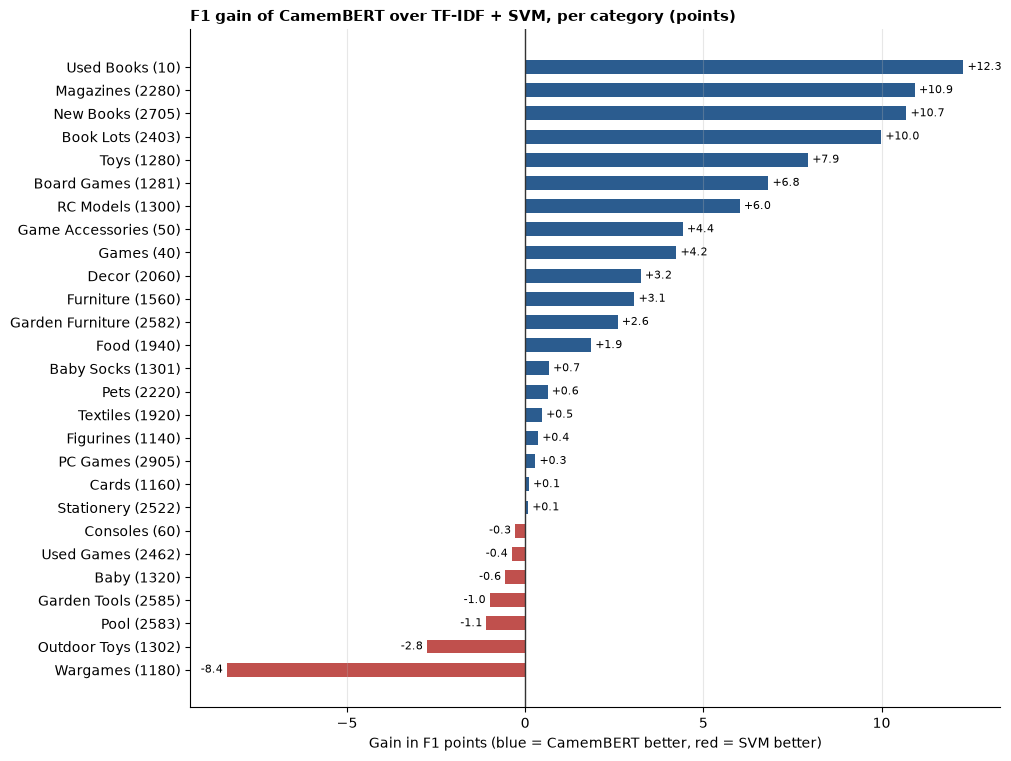

In [6]:
svm_scores               = compute_per_class_metrics(y_true, pred_svm, classes)
camembert_scores         = compute_per_class_metrics(y_true, pred_camembert, classes)

per_class                = pd.DataFrame({
    "Code":         classes,
    "Category":     [CATEGORY_NAMES[c] for c in classes],
    "SVM F1":       svm_scores["f1"],
    "CamemBERT F1": camembert_scores["f1"],
})
per_class["Gain"]        = per_class["CamemBERT F1"] - per_class["SVM F1"]
per_class                = per_class.sort_values("Gain")

fig, ax                  = plt.subplots(figsize=(10, 7.5), constrained_layout=True)
labels                   = [f"{n} ({c})" for n, c in zip(per_class["Category"], per_class["Code"])]
colors                   = ["#2b5c8f" if g >= 0 else "#c0504d" for g in per_class["Gain"]]
bars                     = ax.barh(labels, per_class["Gain"] * 100, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{g * 100:+.1f}" for g in per_class["Gain"]], padding=3, fontsize=8)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("F1 gain of CamemBERT over TF-IDF + SVM, per category (points)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Gain in F1 points (blue = CamemBERT better, red = SVM better)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()


### Analysis

- CamemBERT beats TF-IDF + SVM by 3.4 points of weighted F1 (0.8765 against 0.8430) and 2.7 points of macro F1.
- The largest gains are on the book categories: Used Books +12.3 points, Magazines +10.9, New Books +10.7, Book Lots +10.0. These were the weakest categories for the SVM.
- Toys, Board Games and RC Models also gain 6 to 8 points.
- The SVM is still better on a few categories, mainly Wargames (-8.4) and Outdoor Toys (-2.8). These depend on rare, specific words (*warhammer*, *heroclix*, *trampoline*) that the SVM uses directly.

## 5. Most confused pairs

The 8 category pairs CamemBERT mixes up most often, with the number of errors for each model.

In [7]:
def confusion_counts(pred):
    errors = pd.DataFrame({"true": y_true, "pred": pred})
    errors = errors[errors["true"] != errors["pred"]]
    return errors.value_counts(["true", "pred"])

camembert_pairs          = confusion_counts(pred_camembert)
svm_pairs                = confusion_counts(pred_svm)

top                      = camembert_pairs.head(8)
pairs                    = pd.DataFrame({
    "True category":    [f"{CATEGORY_NAMES[t]} ({t})" for t, _ in top.index],
    "Predicted as":     [f"{CATEGORY_NAMES[p]} ({p})" for _, p in top.index],
    "CamemBERT errors": top.to_numpy(),
    "SVM errors":       [svm_pairs.get(pair, 0) for pair in top.index],
})
print(f"Total errors: CamemBERT {(pred_camembert != y_true).sum()}, SVM {(pred_svm != y_true).sum()}")
display(pairs.style.hide(axis="index"))


Total errors: CamemBERT 2082, SVM 2656


True category,Predicted as,CamemBERT errors,SVM errors
Used Books (10),New Books (2705),97,78
Toys (1280),Board Games (1281),63,51
New Books (2705),Used Books (10),58,90
Book Lots (2403),Used Books (10),50,77
Book Lots (2403),Magazines (2280),46,95
Board Games (1281),Toys (1280),44,91
Toys (1280),Outdoor Toys (1302),43,27
Toys (1280),Figurines (1140),40,37


### Analysis

- CamemBERT makes 2082 errors against 2656 for the SVM (22% fewer).
- The hardest pairs are still the same: Used Books and New Books, Toys and Board Games, Book Lots and Used Books.
- CamemBERT halves the confusion between Book Lots and Magazines (46 errors against 95) and between Board Games and Toys (44 against 91).
- It confuses Used Books with New Books more often than the SVM (97 against 78). Both are books with similar titles, and only the condition differs.

## Conclusion

- CamemBERT is the best single text model: 0.8765 weighted F1 on validation.
- It helps most where the SVM was weakest, the book categories, because it reads words in context instead of counting them.
- The cost is training time: about 2 hours on a laptop GPU, against a few seconds for the SVM.